# Freight Rate Prediction — Exploratory Data Analysis

**Assessment:** predict `posted_rate` (USD) for truckload freight shipments.

This notebook is my working EDA. I use it to understand the data, surface
data-quality problems, and justify the modelling choices that end up in `src/`.
The reusable logic (feature engineering, training, prediction) lives in the
package so training and serving share one code path; this notebook is the
narrative behind those decisions.

**Contents**
1. Load the data and check its shape
2. The target: what are we predicting?
3. What drives the rate? (distance, equipment, lane)
4. Time effects (trend + weekly rhythm)
5. Data-quality audit (bad weights, missing values, distance sanity)
6. Validation strategy — why a temporal split
7. Takeaways that flow into the model

## 1. Load the data and check its shape

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (8, 4.5)
ACCENT = "#064A56"

DATA = "../data"
train = pd.read_csv(f"{DATA}/train_test.csv", parse_dates=["date"])
val = pd.read_csv(f"{DATA}/validation.csv", parse_dates=["date"])

print(f"train rows: {len(train):,}   columns: {list(train.columns)}")
print(f"val   rows: {len(val):,}   columns: {list(val.columns)}")
train.head()

train rows: 48,000   columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']
val   rows: 12,000   columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


The training set has the target `posted_rate`; the validation set does not (that
is what we predict). First thing I always check on a time-series-flavoured
problem: **how do the date ranges line up?**

In [2]:
print("train dates:", train.date.min().date(), "->", train.date.max().date())
print("val   dates:", val.date.min().date(), "->", val.date.max().date())

train dates: 2025-01-01 -> 2025-10-31
val   dates: 2025-11-01 -> 2025-12-31


**Important:** the validation window (Nov–Dec 2025) sits entirely *after* the
training window (Jan–Oct 2025). The task is genuinely forecasting the future,
which is going to dictate how I split for local validation later.

## 2. The target: what are we predicting?

In [3]:
train.posted_rate.describe()

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

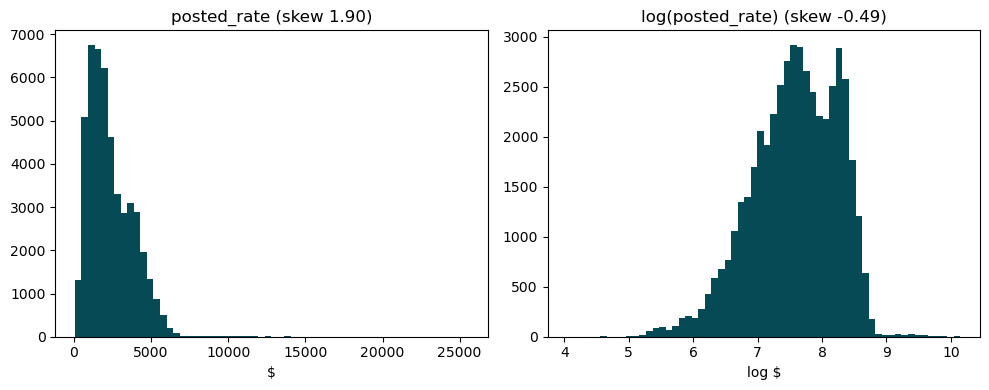

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(train.posted_rate, bins=60, color=ACCENT)
axes[0].set_title(f"posted_rate (skew {train.posted_rate.skew():.2f})")
axes[0].set_xlabel("$")
axes[1].hist(np.log(train.posted_rate), bins=60, color=ACCENT)
axes[1].set_title(f"log(posted_rate) (skew {np.log(train.posted_rate).skew():.2f})")
axes[1].set_xlabel("log $")
plt.tight_layout()
plt.show()

The raw target is strongly right-skewed (skew ~1.9) — a long tail of expensive
long-haul loads. Taking the **log** nearly symmetrises it (skew ~-0.5). That is
a strong hint to model `log(posted_rate)`: it makes the error relative (better
for a price) and guarantees positive predictions, which the scorer requires.

## 3. What drives the rate?

In [5]:
num = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
       "distance", "weight", "market_index", "quote_signal"]
train[num + ["posted_rate"]].corr()["posted_rate"].sort_values()

delivery_lon   -0.257086
pickup_lon     -0.255058
delivery_lat   -0.091970
pickup_lat     -0.090873
quote_signal   -0.039858
market_index    0.034165
weight          0.034840
distance        0.908519
posted_rate     1.000000
Name: posted_rate, dtype: float64

`distance` is far and away the strongest linear predictor (**r = 0.91**).
Everything else is a second-order adjustment. Let's see that relationship.

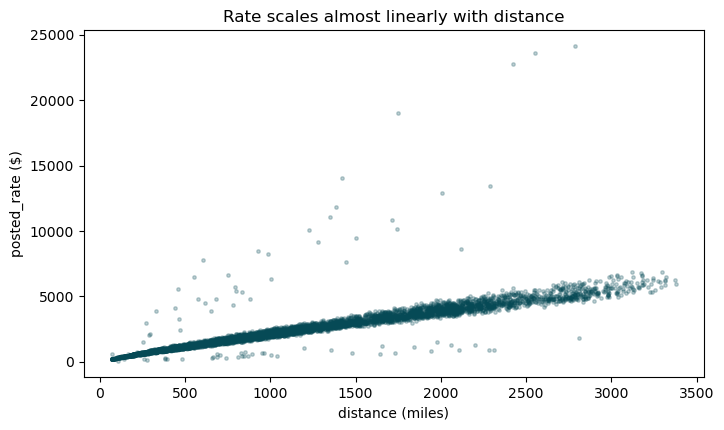

In [6]:
s = train.sample(6000, random_state=0)
plt.scatter(s.distance, s.posted_rate, s=6, alpha=0.25, color=ACCENT)
plt.xlabel("distance (miles)"); plt.ylabel("posted_rate ($)")
plt.title("Rate scales almost linearly with distance")
plt.show()

Near-linear. So the natural unit to reason about is **rate per mile** — it
strips out the distance effect and exposes everything else.

In [7]:
train["rpm"] = train.posted_rate / train.distance
train.groupby("equipment").rpm.mean().sort_values()

equipment
Dry Van    2.115401
Flatbed    2.294729
Reefer     2.383376
Name: rpm, dtype: float64

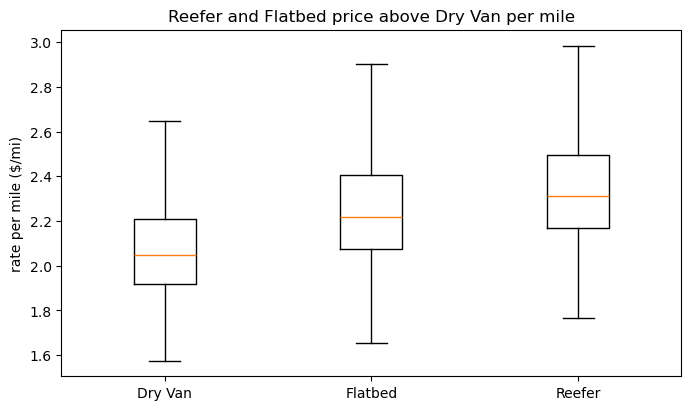

In [8]:
order = ["Dry Van", "Flatbed", "Reefer"]
data = [train.loc[train.equipment == e, "rpm"].clip(upper=5) for e in order]
plt.boxplot(data, tick_labels=order, showfliers=False)
plt.ylabel("rate per mile ($/mi)")
plt.title("Reefer and Flatbed price above Dry Van per mile")
plt.show()

Clear equipment premium: **Dry Van < Flatbed < Reefer** per mile. Refrigerated
freight costing the most matches real-world freight economics, which is a good
sign the data is realistic. Equipment is going into the model as a category.

What about the **lane** (origin → destination pair)?

In [9]:
train["lane"] = train.pickup + " -> " + train.delivery
print("distinct lanes:", train.lane.nunique())
train.groupby("lane").rpm.mean().sort_values(ascending=False).head(8)

distinct lanes: 4014


lane
Dallas -> Grand Rapids        6.643753
Montgomery -> Birmingham      5.261964
Detroit -> Fort Wayne         4.872794
Chattanooga -> Little Rock    4.685977
Washington -> Dayton          4.448272
Jacksonville -> Savannah      4.272463
Providence -> New York        4.229703
Dallas -> St. Louis           4.197029
Name: rpm, dtype: float64

Hundreds of distinct lanes with meaningfully different per-mile pricing — a
strong regional signal. Too high-cardinality to one-hot sensibly, which is
another reason to reach for a gradient-boosting model that handles categoricals
natively.

## 4. Time effects

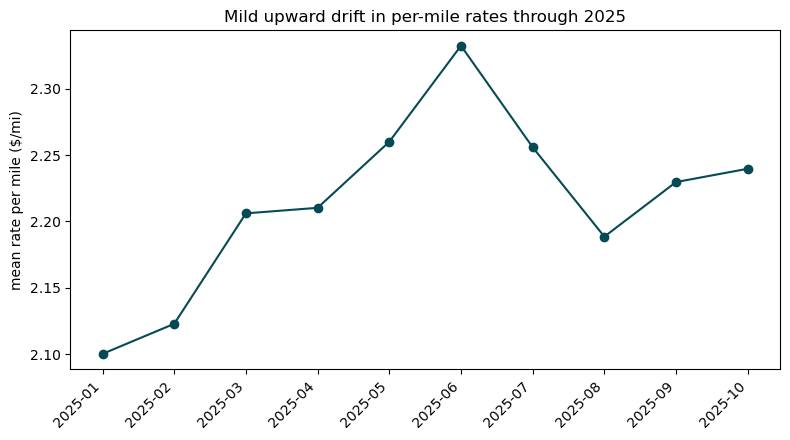

date
2025-01    2.100221
2025-02    2.122885
2025-03    2.206132
2025-04    2.210309
2025-05    2.260106
2025-06    2.332484
2025-07    2.255952
2025-08    2.188584
2025-09    2.229725
2025-10    2.239763
Freq: M, Name: rpm, dtype: float64

In [10]:
monthly = train.groupby(train.date.dt.to_period("M")).rpm.mean()
plt.plot(range(len(monthly)), monthly.values, marker="o", color=ACCENT)
plt.xticks(range(len(monthly)), [str(p) for p in monthly.index], rotation=45, ha="right")
plt.ylabel("mean rate per mile ($/mi)")
plt.title("Mild upward drift in per-mile rates through 2025")
plt.tight_layout(); plt.show()
monthly

In [11]:
dow = train.groupby(train.date.dt.dayofweek).rpm.mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow

Mon    2.196373
Tue    2.213440
Wed    2.248383
Thu    2.244592
Fri    2.214910
Sat    2.195747
Sun    2.192251
Name: rpm, dtype: float64

There is a gentle upward drift across the year and a small mid-week bump. Both
are real but subtle. I will encode the date as a linear "day index" (for the
trend) plus cyclical month and day-of-week features (so December sits next to
January, Sunday next to Monday) rather than as raw integers.

## 5. Data-quality audit

In [12]:
print("weight <= 0 :", (train.weight <= 0).sum(), " | min weight:", train.weight.min())
print("weight NaN  :", train.weight.isna().sum(), "(train)", val.weight.isna().sum(), "(val)")
print("market_index NaN:", train.market_index.isna().sum(), "(train)", val.market_index.isna().sum(), "(val)")
print("duplicate load_id:", train.load_id.duplicated().sum())
print("posted_rate <= 0:", (train.posted_rate <= 0).sum())

weight <= 0 : 292  | min weight: -47500.0
weight NaN  : 300 (train) 165 (val)
market_index NaN: 374 (train) 249 (val)
duplicate load_id: 0
posted_rate <= 0: 0


Three concrete problems:

1. **Impossible weights** — 292 rows at or below zero, down to **-47,500 lb**.
   Physically meaningless. I clip `weight` to a plausible freight band
   (1,000–48,000 lb) and treat out-of-band values as missing.
2. **Missing values** — a few hundred missing weights and market indices in both
   splits. Rather than impute-and-hope, I keep them as NaN and let LightGBM route
   missing values natively, so **no row is dropped at prediction time**.
3. No duplicate IDs and no bad targets — good.

One more check I always do with a distance column: does it agree with the
straight-line distance implied by the coordinates?

In [13]:
def haversine(lat1, lon1, lat2, lon2, R=3958.8):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    d = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.clip(np.sqrt(d), 0, 1))

train["hav"] = haversine(train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon)
ratio = (train.distance / train.hav).replace([np.inf, -np.inf], np.nan)
print("median distance / haversine ratio:", round(ratio.median(), 3))
ratio.describe()

median distance / haversine ratio: 1.182


count    48000.000000
mean         1.194681
std          0.143541
min          1.058090
25%          1.164765
50%          1.182231
75%          1.204765
max          9.634919
dtype: float64

Billed `distance` runs about **1.17×** the straight-line distance. That is not
an error — it is real road **circuity** (roads don't go in straight lines). So I
**trust the billed distance** as the primary feature and only *add* haversine and
the circuity ratio as secondary signals, instead of overwriting one with the
other.

## 6. Validation strategy — why a temporal split

The validation set is the future (Nov–Dec) relative to training (Jan–Oct). If I
validated locally with a **random** shuffle split, the model would see Sep/Oct
rows during training and be scored on Jan rows — leaking future information and
flattering the metrics.

So my local holdout imitates the real task: sort by date, **hold out the most
recent 20% by date**, train on the earlier 80%. Below is the cutoff that
produces.

In [14]:
cutoff = train.date.quantile(0.80)
tr = train[train.date <= cutoff]
ho = train[train.date > cutoff]
print("cutoff date      :", cutoff.date())
print("train (<= cutoff):", f"{len(tr):,}", "rows, up to", tr.date.max().date())
print("holdout (> cutoff):", f"{len(ho):,}", "rows, from", ho.date.min().date())

cutoff date      : 2025-08-31
train (<= cutoff): 38,477 rows, up to 2025-08-31
holdout (> cutoff): 9,523 rows, from 2025-09-01


That gives a Sep–Oct holdout — a clean stand-in for the Nov–Dec target period.
`src/train.py` implements exactly this split, then refits on all data before
scoring the real validation set. On the holdout the model lands at **~5.7%
MAPE** and **R² 0.82**.

## 7. Takeaways that flow into the model

Everything above maps directly to decisions in `src/`:

| Finding | Decision in the model |
| ------- | --------------------- |
| Target is right-skewed | train on `log(posted_rate)` |
| Distance dominates, near-linear | keep billed distance as primary feature |
| Distance ≈ 1.17× haversine | add haversine + circuity as secondary signals |
| Equipment premium (Reefer > Flatbed > Dry Van) | equipment as a category |
| Lane is a strong regional signal (high cardinality) | lane as a category; use LightGBM |
| Mild trend + weekly rhythm | day index + cyclical month/day-of-week |
| Bad / missing weights & signals | clip weight, keep NaNs, booster handles them |
| Validation window is the future | temporal forward split, then refit on all data |

The model itself is **LightGBM** — it captures the non-linear interactions among
equipment, lane and market signals, handles the high-cardinality lane and the
missing values natively, and is quick to train. Training, prediction and the
fixed December chart are all driven from `src/`.